# Part 1 – Website and app analysis

This notebook brings together everything about Grab Malaysia's **own digital channels**:

* **Section A – Websites.** Speed and quality scores from Google PageSpeed Insights, plus a basic on-page SEO check
  (title, description, headings, image alt text) for five Grab Malaysia sites.
* **Section B – App reviews.** Star ratings and written reviews of the Grab app on **Google Play** and the **Apple App Store**.
* **Section C – Support and interactive features.** How reviewers rate their experience with chatbots, agents and the help centre.

Everything this notebook produces is saved in this folder (`website and app analysis/`):
`tables/` (CSV), `figures/` (PNG, 300 dpi) and `data/` (clean review table, raw PageSpeed results).
**`README.md`** in this folder has the written findings and figure captions for the report.

The code is in `src/findings.py` (`run_web`) and `src/app_reviews.py`.

In [1]:
import sys, os, pandas as pd
from pathlib import Path
from IPython.display import Image, display
here = Path.cwd()
ROOT = here.parent if here.name in ("website and app analysis", "notebooks") else here
os.chdir(ROOT); sys.path.insert(0, str(ROOT))
pd.set_option("display.max_colwidth", 140); pd.set_option("display.width", 200)
from src.findings import run_web
from src import app_reviews

WA = Path("website and app analysis")
show = lambda name: display(Image(str(WA / "figures" / f"{name}.png"), width=760))

# False = use the reviews already collected on 18 Nov 2026 (recommended).
# True  = fetch fresh reviews again (free, 14 requests; see the robots.txt note in Section B).
RUN_APP_COLLECTION = False

## Section A – Websites (Google PageSpeed Insights + on-page SEO)
The tests themselves were run in `notebooks/history/01_data_collection.ipynb` (Section A) on 4 Nov 2026.
Each site was tested 3 times on mobile and 3 times on desktop, and we report the **median**. Here we summarise and chart the results.

**How to read the scores:** 90–100 is good, 50–89 needs improvement, 0–49 is poor (Google's bands).

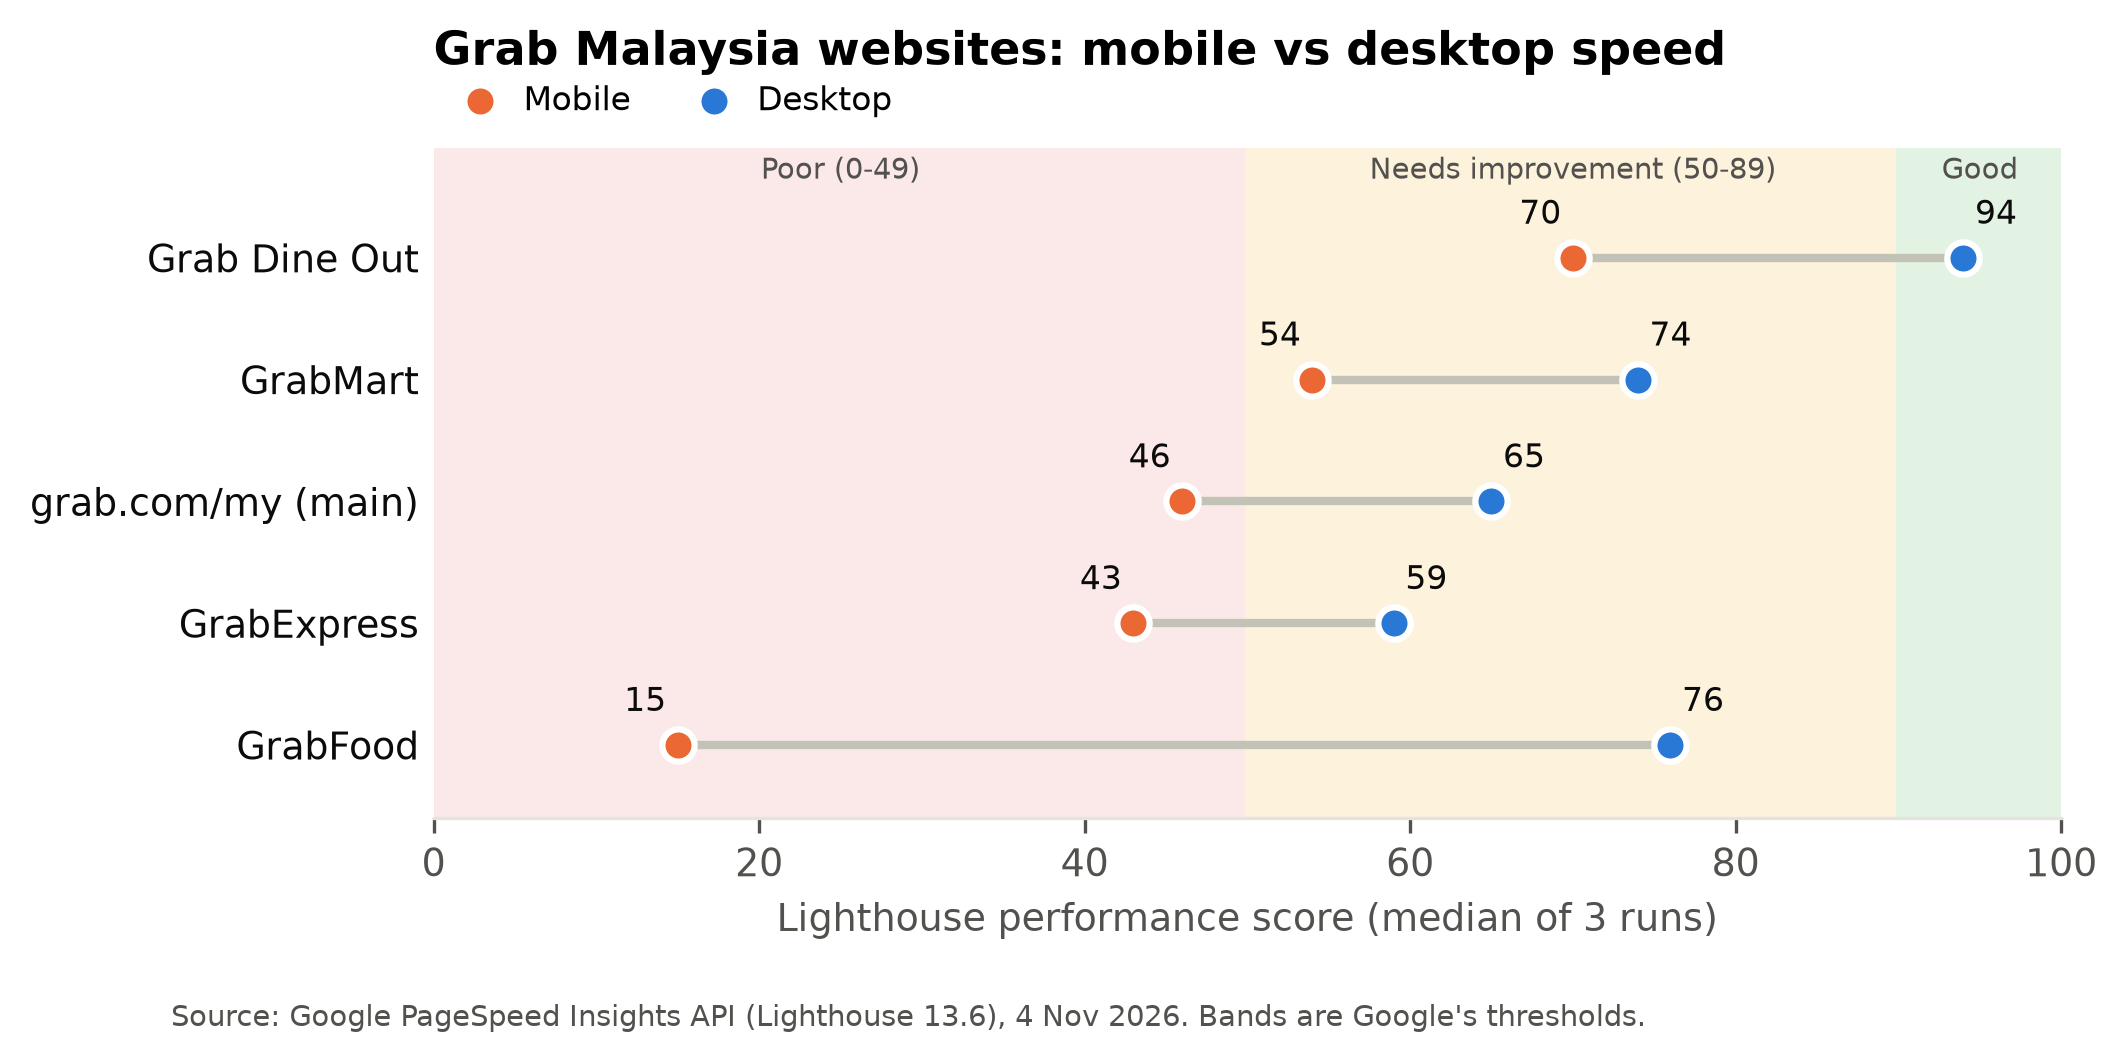

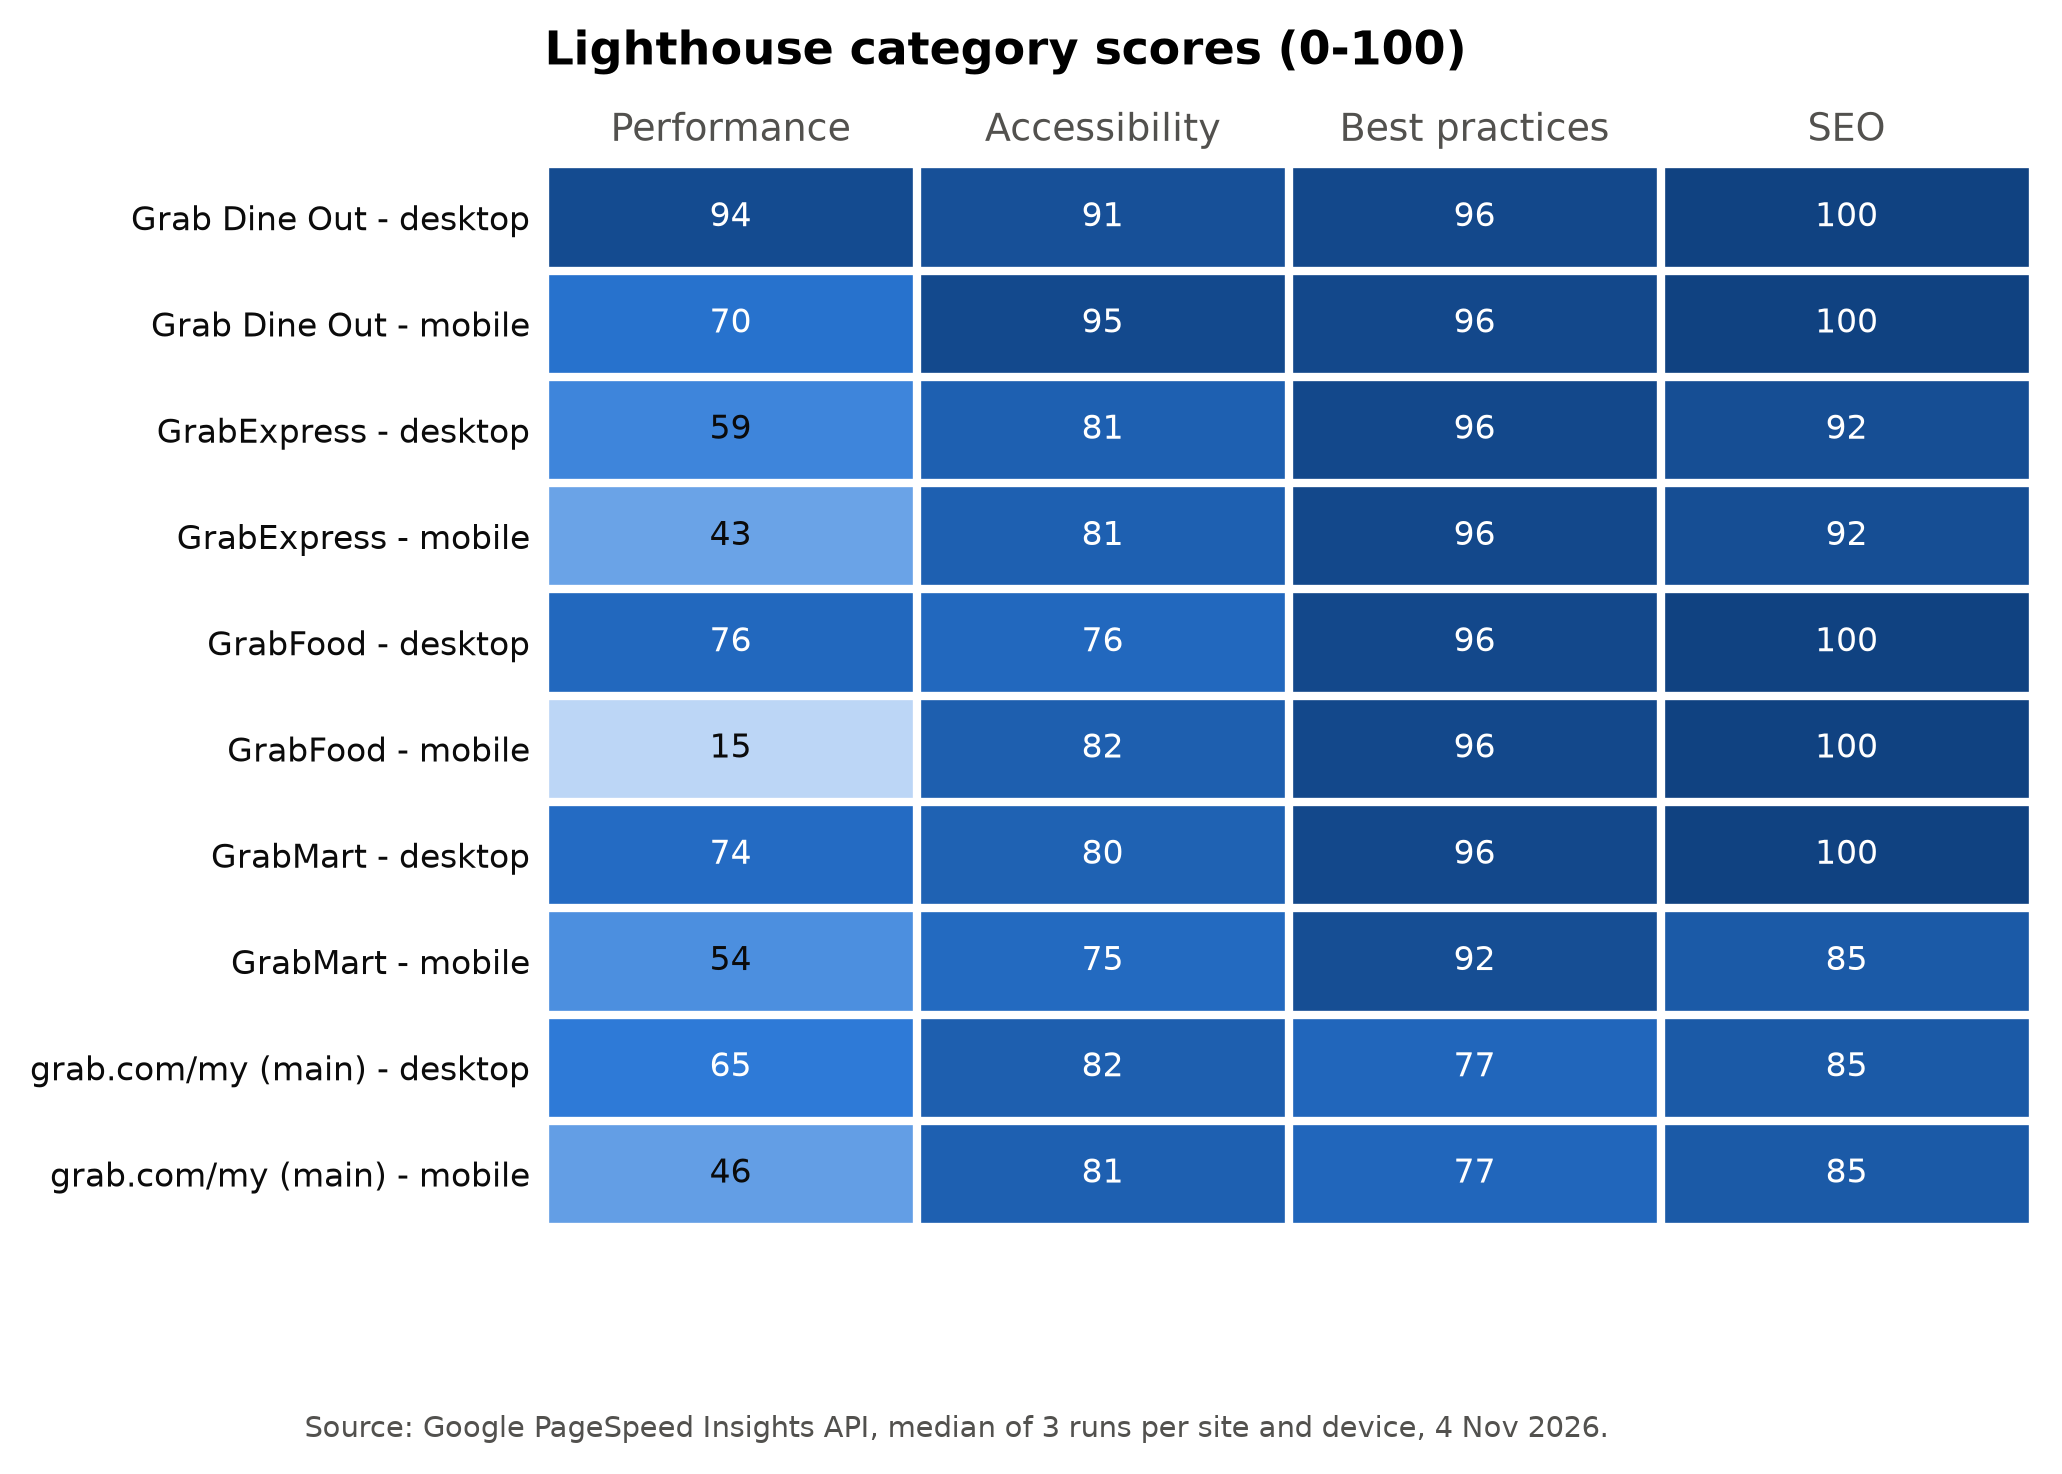

,site,device,performance,accessibility,best_practices,seo,lab_LCP_s,lab_TBT_ms,lab_CLS,real_users_LCP,real_users_INP,real_users_CLS,real_users_overall,performance_rating
0,Grab Dine Out,desktop,94.0,91.0,96.0,100.0,1.1,112,0.007,FAST,FAST,FAST,FAST,good (90-100)
1,Grab Dine Out,mobile,70.0,95.0,96.0,100.0,11.2,148,0.001,AVERAGE,FAST,FAST,AVERAGE,needs improvement (50-89)
2,GrabExpress,desktop,59.0,81.0,96.0,92.0,2.4,535,0.000,FAST,FAST,FAST,FAST,needs improvement (50-89)
3,GrabExpress,mobile,43.0,81.0,96.0,92.0,12.2,784,0.000,FAST,FAST,FAST,FAST,poor (0-49)
4,GrabFood,desktop,76.0,76.0,96.0,100.0,1.7,369,0.000,FAST,FAST,SLOW,SLOW,needs improvement (50-89)
5,GrabFood,mobile,15.0,82.0,96.0,100.0,24.7,2338,0.456,SLOW,AVERAGE,SLOW,SLOW,poor (0-49)
6,GrabMart,desktop,74.0,80.0,96.0,100.0,1.5,535,0.000,FAST,FAST,FAST,AVERAGE,needs improvement (50-89)
7,GrabMart,mobile,54.0,75.0,92.0,85.0,6.2,959,0.000,AVERAGE,AVERAGE,FAST,AVERAGE,needs improvement (50-89)
8,grab.com/my (main),desktop,65.0,82.0,77.0,85.0,3.4,554,0.051,FAST,FAST,FAST,FAST,needs improvement (50-89)
9,grab.com/my (main),mobile,46.0,81.0,77.0,85.0,30.3,648,0.000,FAST,AVERAGE,FAST,AVERAGE,poor (0-49)


In [2]:
web = run_web()
show("web_fig01_performance_mobile_vs_desktop")
show("web_fig02_lighthouse_scores")
display(web["tables"]["web_tab01_performance_summary"])

**On-page SEO check**: the basic things a search engine reads on each page.

In [3]:
display(web["tables"]["web_tab02_onpage_seo_summary"])

,site,http_status,robots_allowed,title_length,meta_description_length,h1_count,h2_count,hreflang_count,img_total,img_missing_alt,has_viewport,issues_found
0,grab.com/my (main),200,True,40.0,129.0,1.0,0.0,18.0,7.0,4.0,True,4 image(s) without alt text
1,GrabFood,200,True,52.0,150.0,0.0,2.0,14.0,23.0,0.0,True,0 H1 tags (1 expected)
2,GrabMart,403,True,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,blocked to crawlers (HTTP 403)
3,GrabExpress,200,True,0.0,0.0,0.0,0.0,6.0,0.0,0.0,True,no <title>; no meta description; 0 H1 tags (1 expected)
4,Grab Dine Out,200,True,44.0,148.0,1.0,1.0,12.0,16.0,0.0,True,no basic issues


## Section B – App reviews (Google Play + App Store)

| Store | App | What we collected |
|---|---|---|
| Google Play | `com.grabtaxi.passenger` | newest 1,000 **English** + newest 1,000 **Malay** reviews, plus the public rating summary |
| App Store | `id647268330` | newest 500 reviews from the **Malaysia** store (Apple's public review feed), plus the public rating summary |

**Important:** Google Play filters reviews by **language, not country**.
* The English reviews come from every country where Grab operates (Indonesia, Philippines, Vietnam, Thailand ...).
* The Malay reviews are mostly from Malaysia.
* The App Store feed is the Malaysia store only.

So we report the **three sources separately**.

**robots.txt note:** both review sources are marked "disallow" for automated crawlers in the stores' robots.txt files.
The group decided (18 Nov 2026) to make a one-off exception for this small academic sample:
* free, 14 requests in total, spaced out, no login;
* reviewer names are replaced by an irreversible code (SHA-256 hash).

Raw files with names stay in `data/raw/app_reviews/`, which is never shared.

In [4]:
app = app_reviews.run(collect=RUN_APP_COLLECTION)
T = app["tables"]
display(T["app_tab01_store_overview"])

,source,store_lifetime_avg_rating (all countries),store_lifetime_n_ratings,sample_n_reviews,sample_avg_rating,sample_pct_1_2_star,sample_pct_4_5_star,sample_from,sample_to,pct_with_developer_reply
0,App Store (Malaysia store),4.73,905812,500,2.76,55.2,41.6,2026-08-12,2026-11-16,NaN
1,Google Play - Malay reviews,4.81,16863093,1000,4.41,13.2,85.0,2026-05-04,2026-11-16,0.4
2,Google Play - English reviews (all markets),4.81,16863093,1000,3.24,42.7,54.1,2026-10-31,2026-11-17,44.0


### B1. Star ratings: recent reviews vs the all-time score
The store pages show 4.8★ (Google Play) and 4.7★ (App Store). Recent **written** reviews are much less positive.
The all-time score includes millions of quick star taps, usually prompted inside the app after a good trip.
Written reviews are more often from people with a problem.

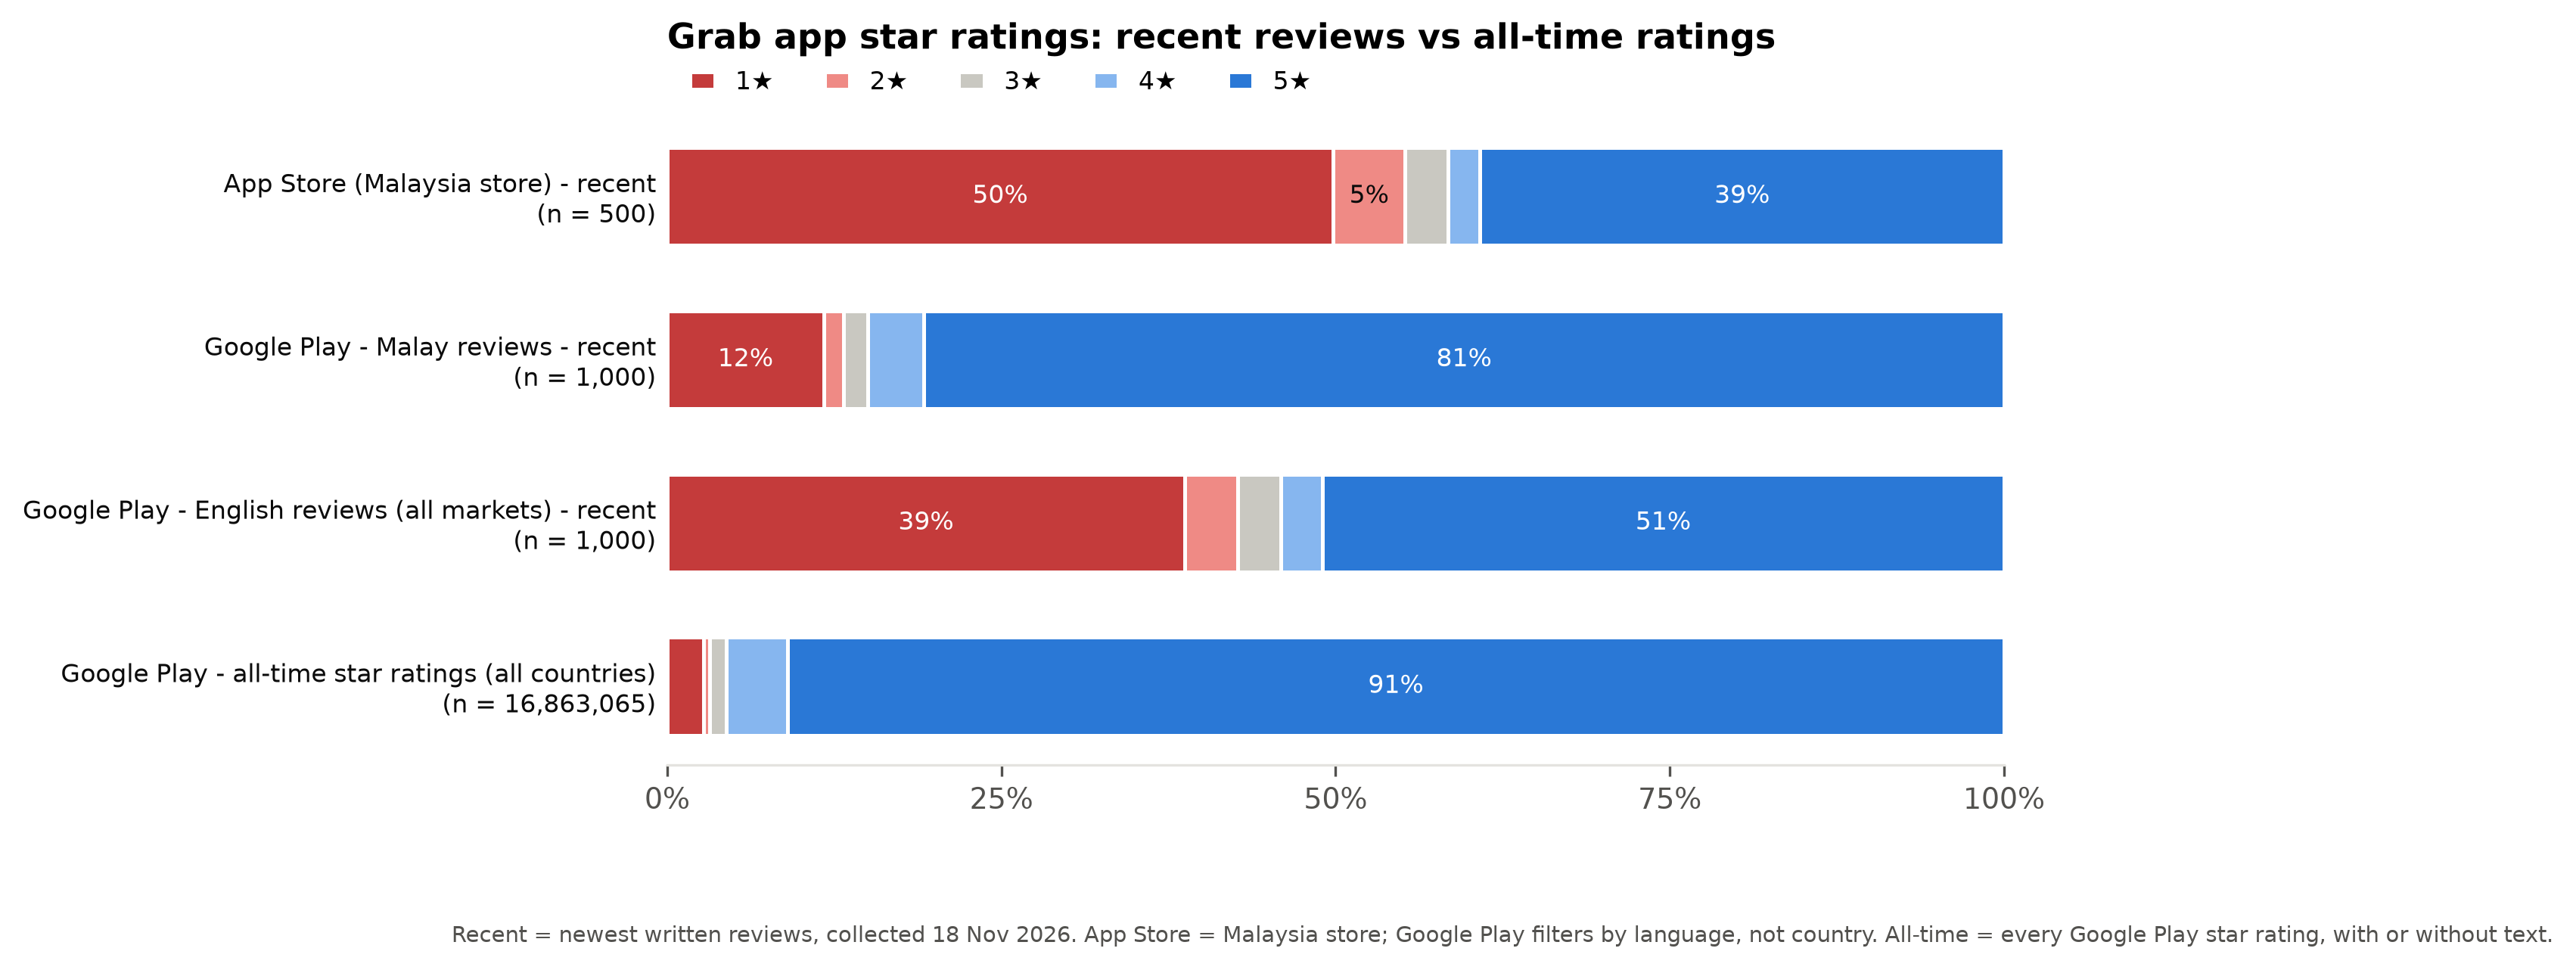

,group,n,pct_1_star,pct_2_star,pct_3_star,pct_4_star,pct_5_star
0,App Store (Malaysia store) - recent,500,49.8,5.4,3.2,2.4,39.2
1,Google Play - Malay reviews - recent,1000,11.7,1.5,1.8,4.2,80.8
2,Google Play - English reviews (all markets) - recent,1000,38.7,4.0,3.2,3.1,51.0
3,Google Play - all-time star ratings (all countries),16863065,2.7,0.5,1.2,4.6,91.0


In [5]:
show("app_fig01_rating_distribution"); display(T["app_tab03_rating_distribution"])

### B2. Ratings over time

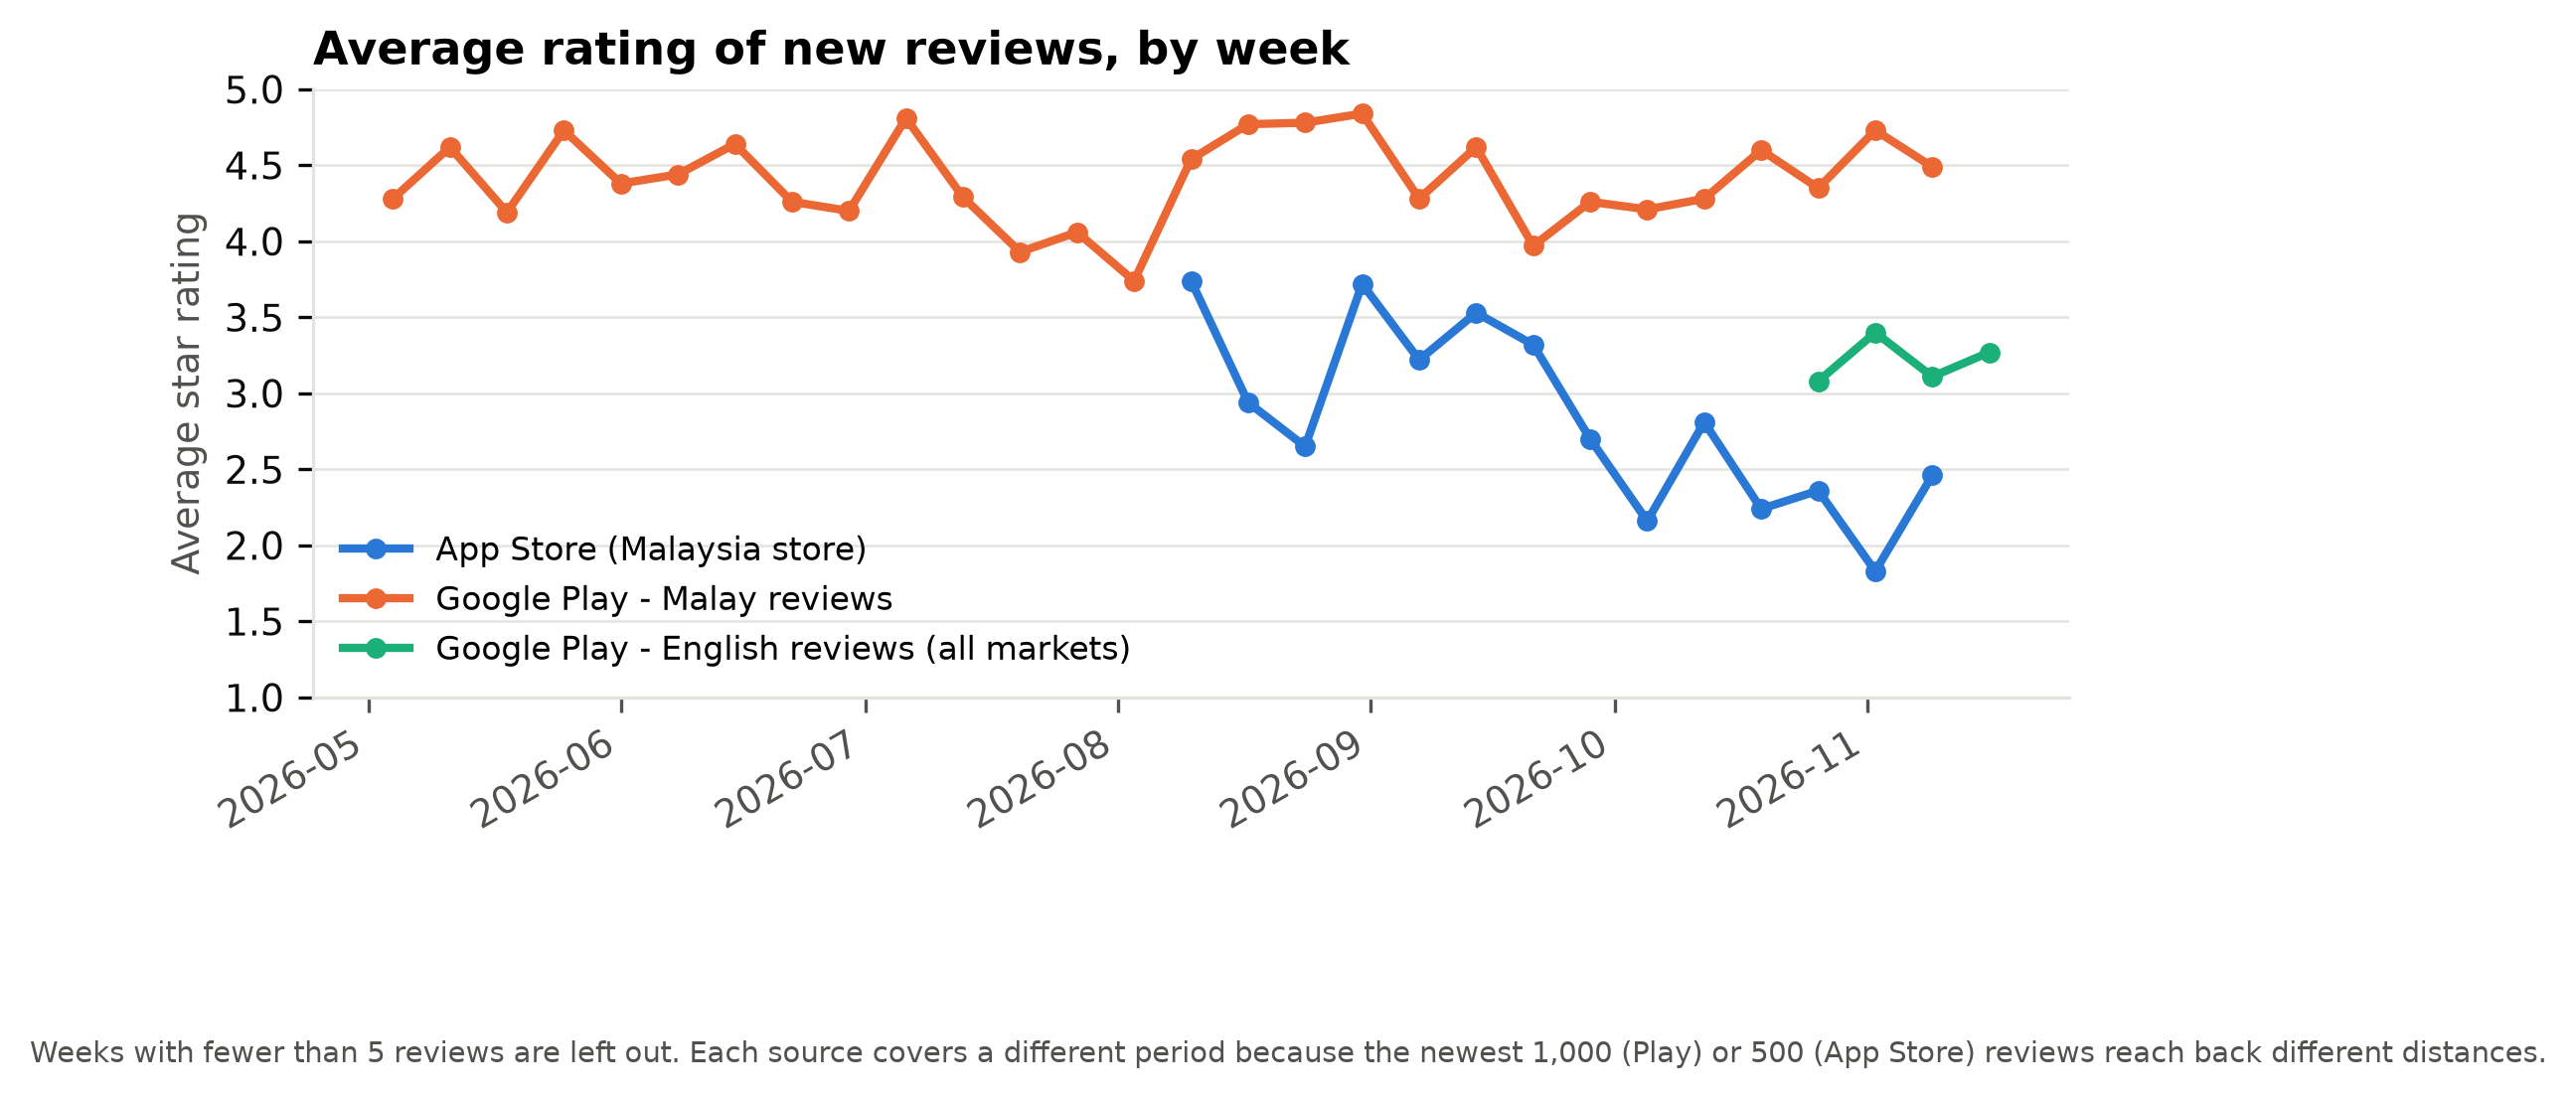

In [6]:
show("app_fig04_weekly_rating")

### B3. What low ratings are about
We use the same English + Malay topic keywords as for the social-media posts (Part 2), so the two parts can be compared directly.

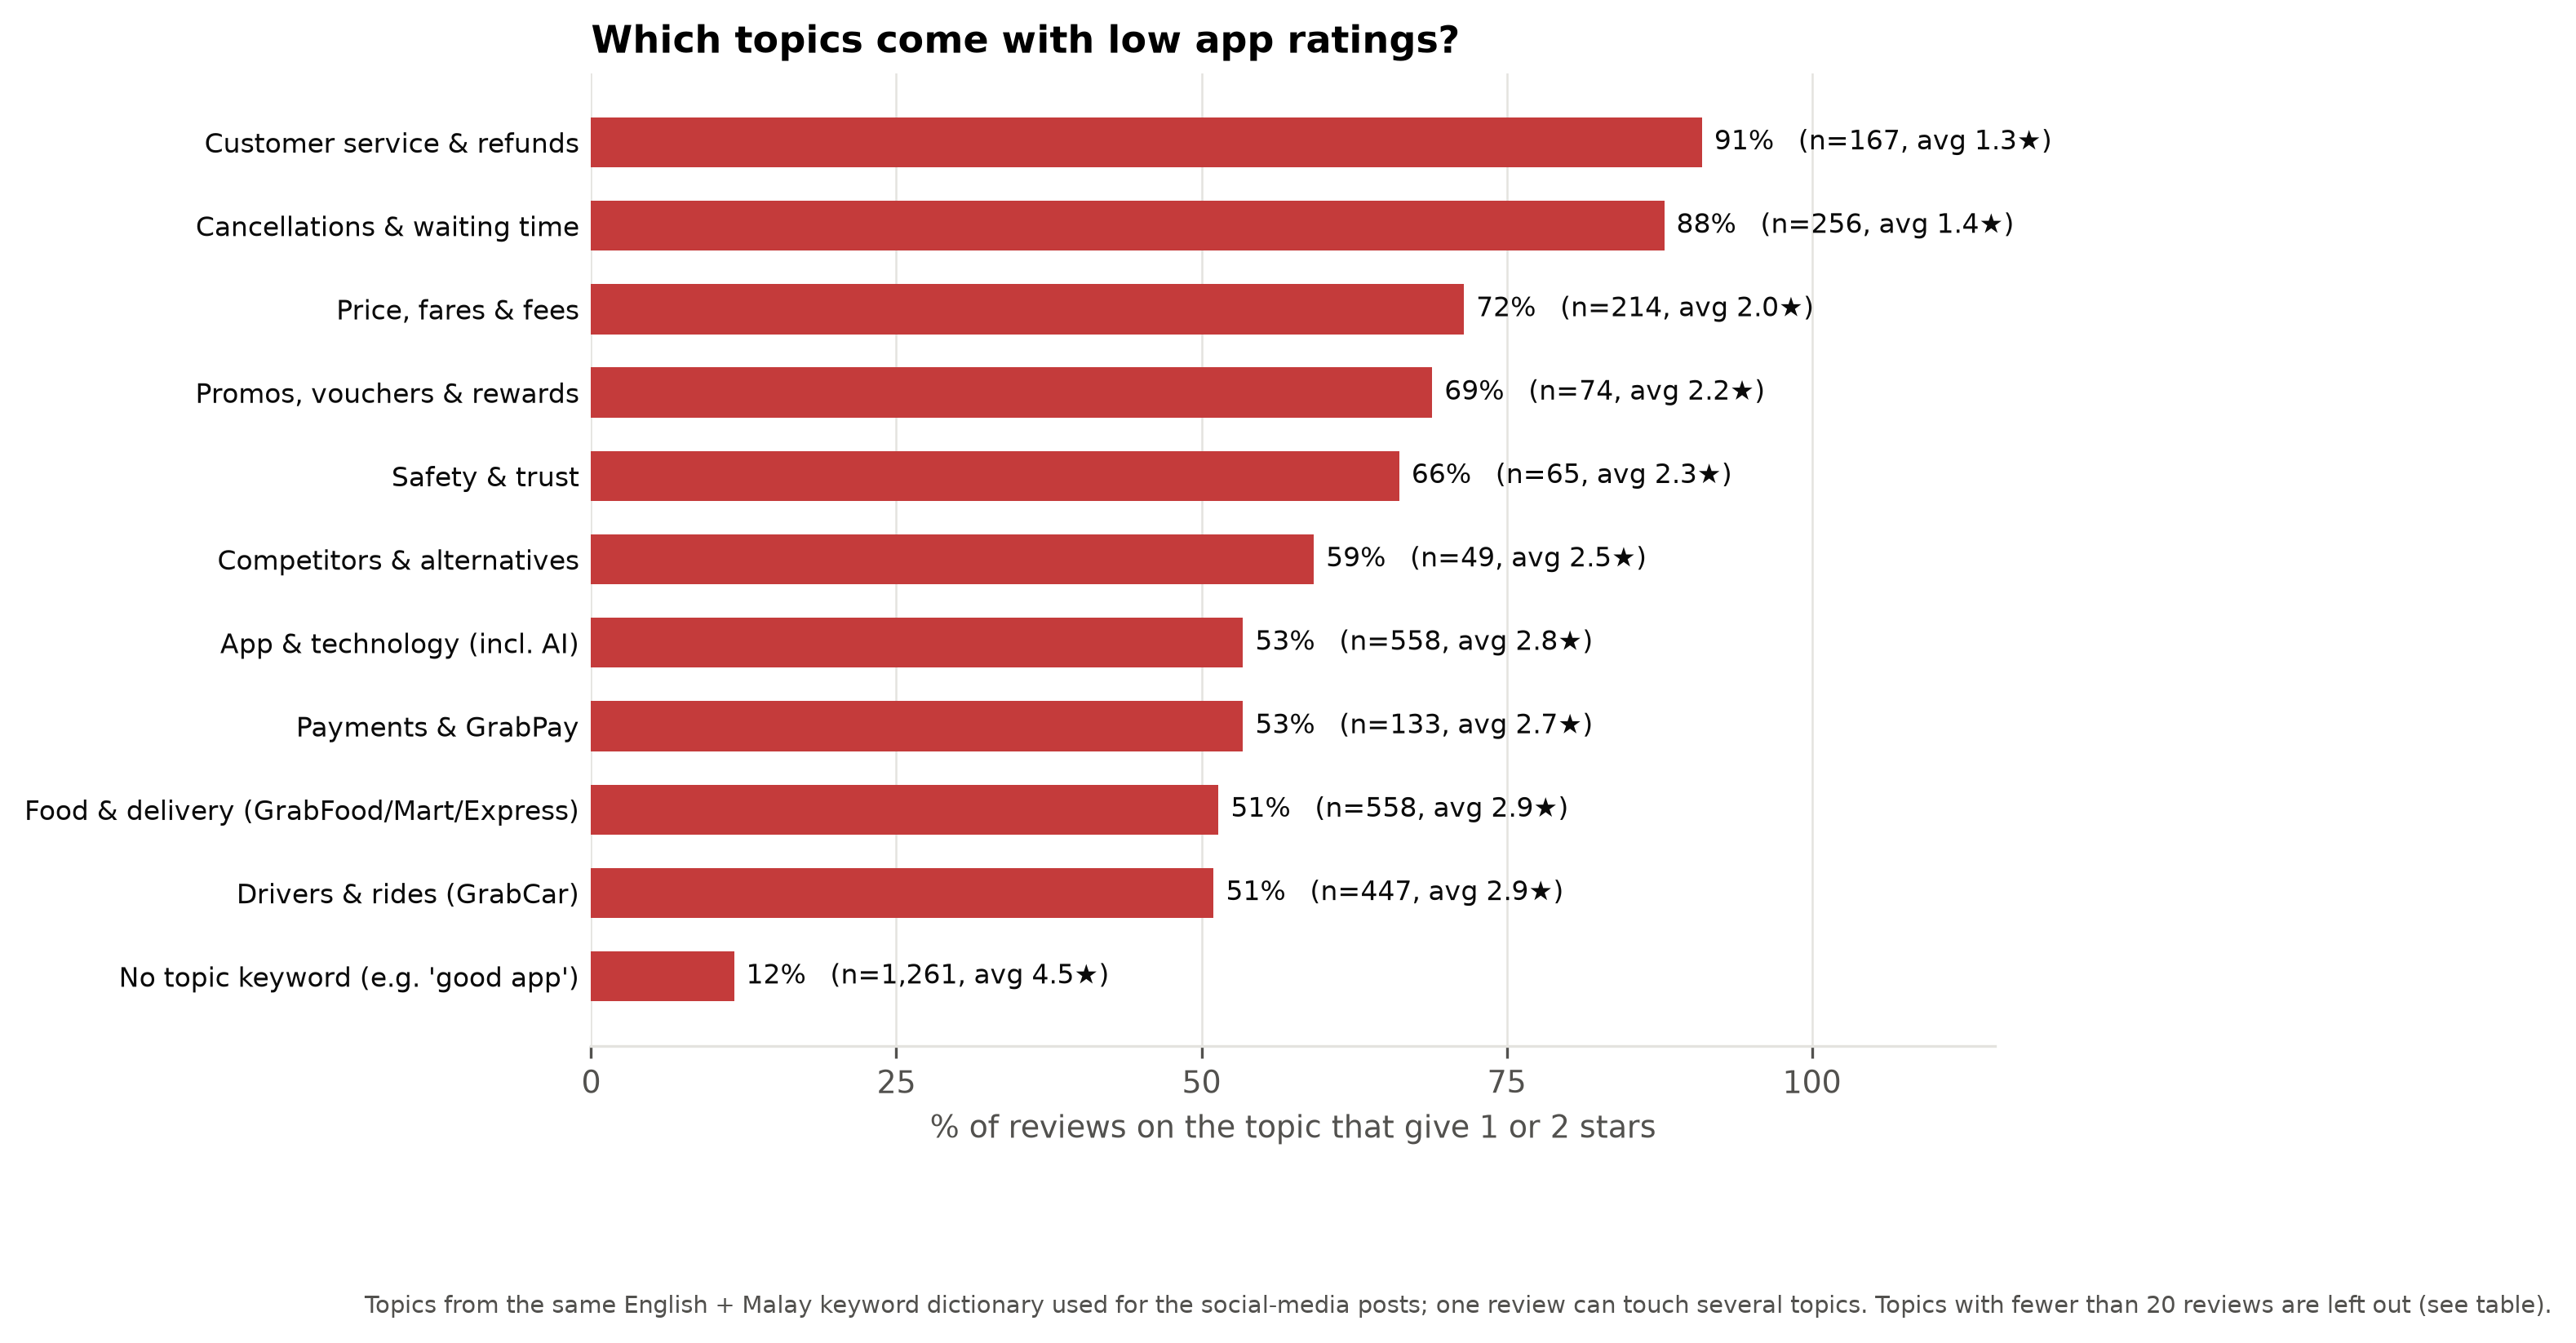

,topic,n_reviews,pct_of_reviews,avg_rating,pct_1_2_star,avg_rating App Store (Malaysia store),avg_rating Google Play - Malay reviews,avg_rating Google Play - English reviews (all markets)
0,Customer service & refunds,167,6.7,1.34,91.0,1.33,1.00,1.34
1,Cancellations & waiting time,256,10.2,1.43,87.9,1.25,2.03,1.43
2,Driver welfare & regulation,5,0.2,1.80,80.0,3.00,NaN,1.00
3,"Price, fares & fees",214,8.6,2.02,71.5,1.65,2.62,2.04
4,"Promos, vouchers & rewards",74,3.0,2.20,68.9,2.36,4.25,1.75
5,Safety & trust,65,2.6,2.32,66.2,1.79,1.00,2.65
6,Competitors & alternatives,49,2.0,2.49,59.2,1.43,4.00,2.59
7,App & technology (incl. AI),558,22.3,2.84,53.4,2.89,3.61,2.62
8,Payments & GrabPay,133,5.3,2.71,53.4,3.13,2.76,2.15
9,Food & delivery (GrabFood/Mart/Express),558,22.3,2.91,51.4,3.00,4.15,2.45


In [7]:
show("app_fig02_low_ratings_by_topic"); display(T["app_tab04_topics"])

### B4. Does Grab reply to reviews? (Google Play only; the App Store feed does not include replies)

In [8]:
display(T["app_tab06_developer_replies_google_play"])

,source,rating,n_reviews,pct_replied,median_reply_hours
0,Google Play - English reviews (all markets),1,387,55.3,26.90
1,Google Play - English reviews (all markets),2,40,57.5,18.20
2,Google Play - English reviews (all markets),3,32,50.0,35.75
3,Google Play - English reviews (all markets),4,31,41.9,24.15
4,Google Play - English reviews (all markets),5,510,34.1,33.40
5,Google Play - Malay reviews,1,117,0.0,NaN
6,Google Play - Malay reviews,2,15,6.7,NaN
7,Google Play - Malay reviews,3,18,0.0,NaN
8,Google Play - Malay reviews,4,42,0.0,NaN
9,Google Play - Malay reviews,5,808,0.4,3.20


### B5. Ratings by language of the review

In [9]:
display(T["app_tab07_by_language"])

,source,lang_group,n_reviews,avg_rating,pct_1_2_star
0,App Store (Malaysia store),en,413,2.81,53.27
1,App Store (Malaysia store),mixed,8,2.75,62.50
2,App Store (Malaysia store),ms,57,2.44,64.91
3,App Store (Malaysia store),other,22,2.55,63.64
4,Google Play - English reviews (all markets),en,822,3.40,38.56
5,Google Play - English reviews (all markets),mixed,12,2.67,58.33
6,Google Play - English reviews (all markets),ms,75,2.16,69.33
7,Google Play - English reviews (all markets),other,91,2.73,56.04
8,Google Play - Malay reviews,en,222,4.82,3.15
9,Google Play - Malay reviews,mixed,30,4.10,20.00


## Section C – Support and interactive features
Reviews that mention **support, chatbot, live chat, agent, help centre, AI assistant or ticket** were counted (the group's keyword list).
"Recommend" is shown separately, because in reviews it nearly always means "I recommend this app", not a recommendation feature.

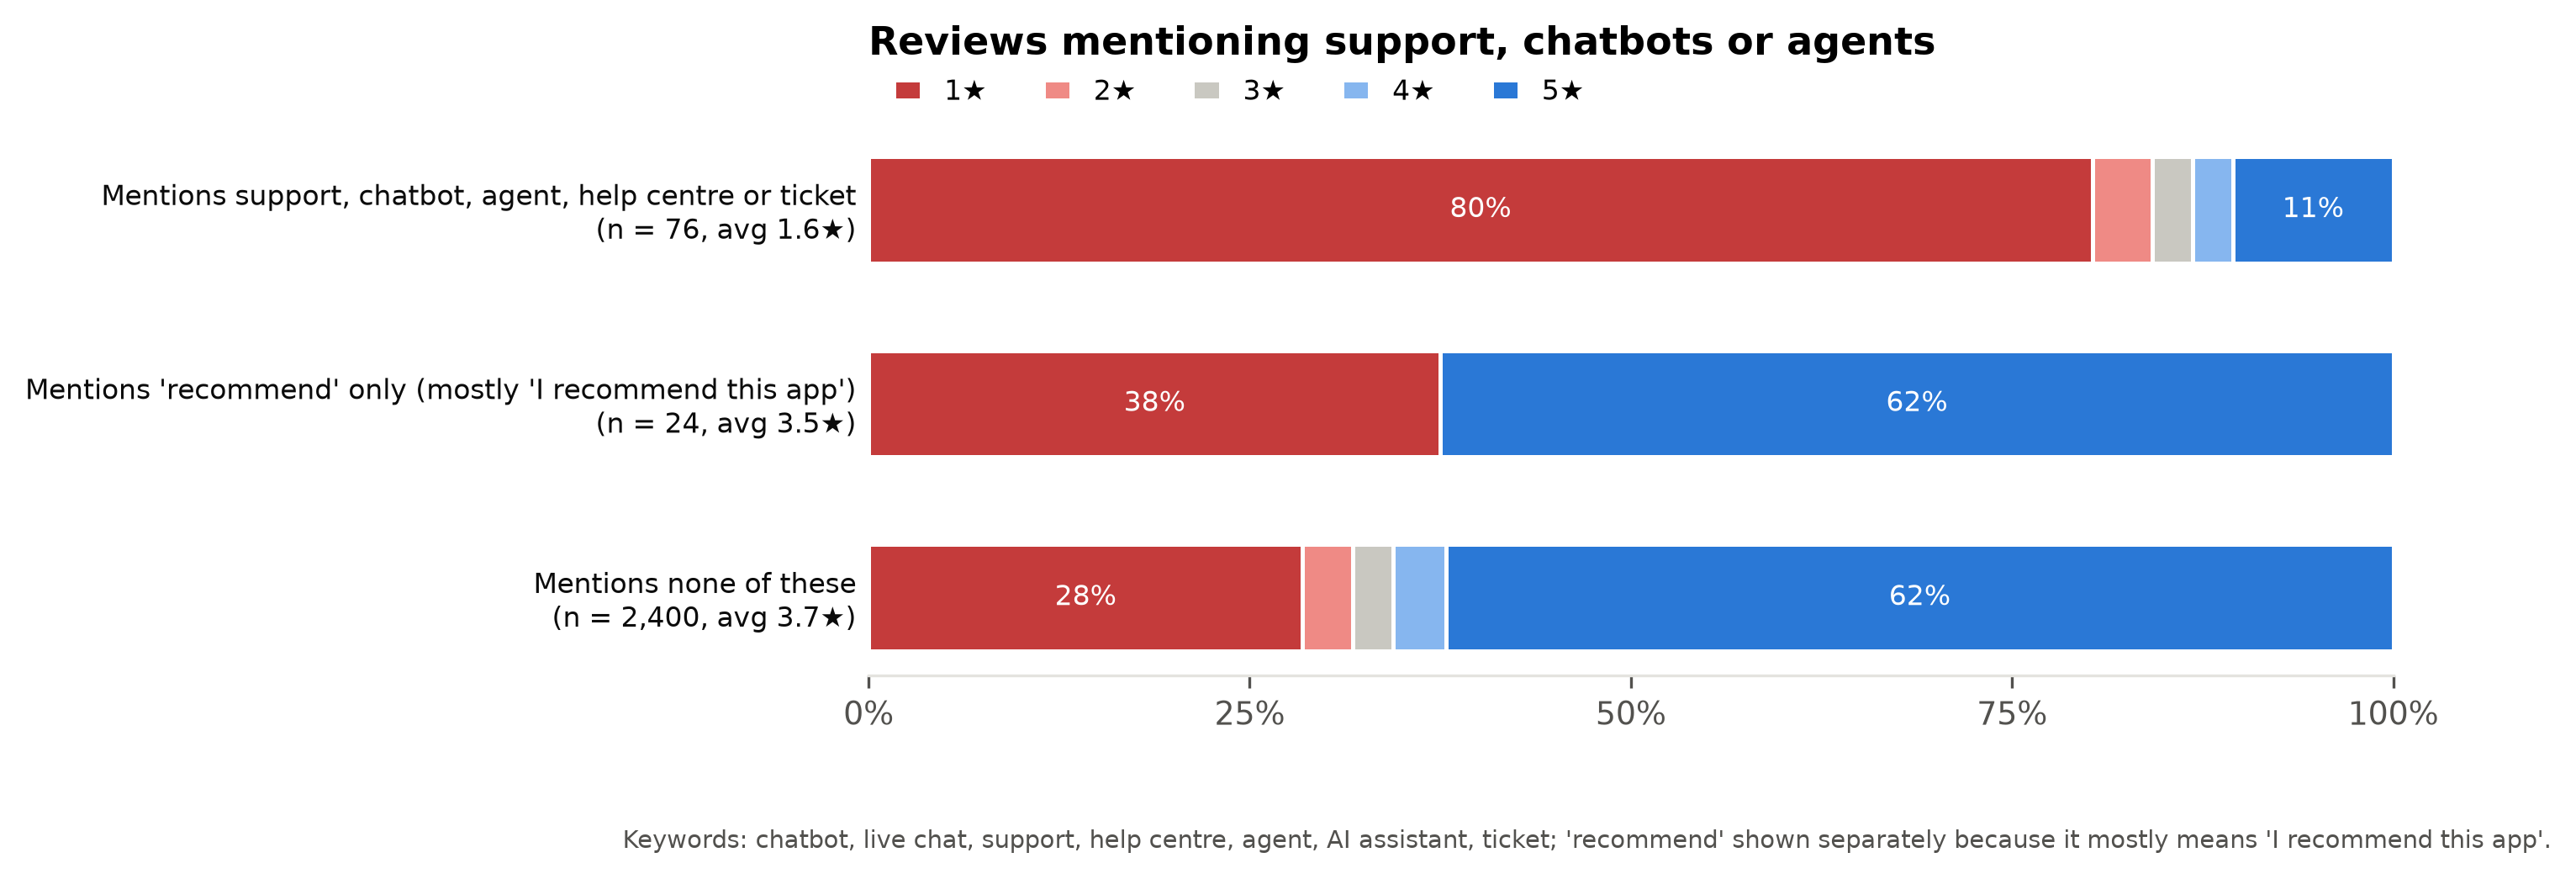

,group,n_reviews,pct_of_reviews,avg_rating,n_1_star,n_2_star,n_3_star,n_4_star,n_5_star,pct_1_2_star
0,Mentions support / interactive features (any keyword),100,4.0,2.05,70,3,2,2,23,73.0
1,"Mentions support, chatbot, agent, help centre or ticket",76,3.0,1.59,61,3,2,2,8,84.2
2,Mentions 'recommend' only (mostly 'I recommend this app'),24,1.0,3.50,9,0,0,0,15,37.5
3,Mentions none of these,2400,96.0,3.68,683,79,64,83,1491,31.8
4,keyword: chatbot,15,0.6,1.07,14,1,0,0,0,100.0
5,keyword: live chat,1,0.0,1.00,1,0,0,0,0,100.0
6,keyword: support,50,2.0,1.80,37,2,2,2,7,78.0
7,keyword: help centre,12,0.5,1.33,11,0,0,0,1,91.7
8,keyword: agent,15,0.6,1.07,14,1,0,0,0,100.0
9,keyword: AI assistant,1,0.0,1.00,1,0,0,0,0,100.0


In [10]:
show("app_fig03_support_mentions"); display(T["app_tab05_support_features"])

### Example reviews (anonymised) for quoting

In [11]:
display(T["app_tab09_example_reviews"])

,group,source,rating,date,text
0,1-2 star,Google Play - English reviews (all markets),1,2026-10-31,"drivernya diajarin lg dong, masa nyedian pembayaran lewat qr gak ada yg ngambil. aneh bngt sih"
1,1-2 star,Google Play - English reviews (all markets),1,2026-11-04,"What's wrong with the app? I've been a Grab user for a decade, ordering rides and food delivery. It started to malfunction October 2026...."
2,1-2 star,Google Play - Malay reviews,1,2026-09-23,"Kenapa ya grab sekarang banya susah mahu daftar, tak macam tu [downcast face with sweat] [downcast face with sweat]"
3,3 star,Google Play - Malay reviews,3,2026-05-21,Screenshoot picture dan pindah ke duitnown juga tidak pernah digunakan ja lagi.
4,3 star,Google Play - Malay reviews,3,2026-06-25,grab driver ok je cuma harga je sebab selalu hari biasa harga rm10 ke rm12 je tiba2 naik sampai rm20
5,3 star,Google Play - English reviews (all markets),3,2026-11-01,I couldn't see where and how did I earn my points.
6,4-5 star,Google Play - Malay reviews,5,2026-05-30,Aku suka graborder bab makanan senang mudah owrner nya sangat baik tapi bab online makanan mahal sangat cuba kurang kan harga mana orang...
7,4-5 star,App Store (Malaysia store),5,2026-09-18,"good. useful apps to go anywhere , order food and anything else !"
8,4-5 star,App Store (Malaysia store),5,2026-08-31,"useful. Such a great app! Simple, useful, and easy to navigate. I really enjoy using it!"
9,mentions support / chatbot,Google Play - English reviews (all markets),1,2026-11-07,"chat bot is not helping, cannot even connect me to a live agent. no option to even contact the merchant or any contact number of the mer..."


## Findings
See **`README.md`** in this folder for the written findings, figure captions and limitations.